# Analysis of Boundary Station Inconsistency
This notebook explores the stations that appear in both the **Hiroshima Bay** and **Aki Nada** station groupings. 
As previously identified, this discrepancy occurs because the stations at the boundary of these two water masses had inconsistent water mass codes recorded across different years in the raw data (1981-2023).

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys
from pathlib import Path

# Add project root to path
sys.path.append('../')
from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig

In [2]:
# Load the merged geo-dataframe
merged_path = ProjectPaths.MERGED_DATA_FILE
print(f'Loading data from {merged_path}...')
gdf = gpd.read_feather(merged_path)

Loading data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


In [3]:
# Filter to the relevant columns
df = gdf[['zettaicode', 'year', 'watercode', 'division', 'watermass_name', 'latitude', 'longitude']].copy()

# Find stations that have ever been classified as both 'Aki Nada' and 'Hiroshima Bay'
# Group by zettaicode and collect unique divisions
station_divisions = df.groupby('zettaicode')['division'].unique()

overlapping_stations = []
for station, divisions in station_divisions.items():
    if 'Aki Nada' in divisions and 'Hiroshima Bay' in divisions:
        overlapping_stations.append(station)

print(f'Found {len(overlapping_stations)} stations that overlap between Aki Nada and Hiroshima Bay:')
print(overlapping_stations)

Found 1 stations that overlap between Aki Nada and Hiroshima Bay:
['00034390']


In [4]:
# Summarize the discrepancies by year for the overlapping stations
overlap_df = df[df['zettaicode'].isin(overlapping_stations)].drop_duplicates(subset=['zettaicode', 'year', 'division'])

# Pivot to see which division was assigned in which year
summary_pivot = overlap_df.pivot_table(
    index='zettaicode', 
    columns='year', 
    values='division', 
    aggfunc=lambda x: ', '.join(x.dropna().unique())
)

summary_pivot

year,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00034390,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,...,Aki Nada,Aki Nada,Hiroshima Bay,Aki Nada,Hiroshima Bay,Hiroshima Bay,Hiroshima Bay,Aki Nada,Aki Nada,Hiroshima Bay


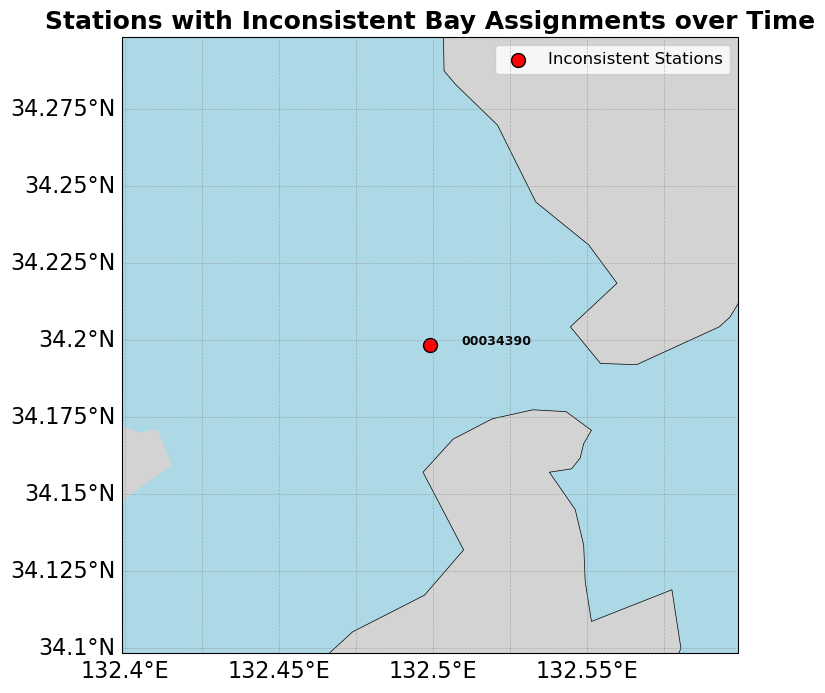

In [5]:
# Visualize the overlapping stations on a map
plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))

# Get unique coordinates for the overlapping stations
coords = df[df['zettaicode'].isin(overlapping_stations)][['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# Map extent
min_lon, max_lon = coords['longitude'].min(), coords['longitude'].max()
min_lat, max_lat = coords['latitude'].min(), coords['latitude'].max()
buffer = 0.1
ax.set_extent([min_lon - buffer, max_lon + buffer, min_lat - buffer, max_lat + buffer], crs=ccrs.PlateCarree())

# Plot the overlapping boundary stations
sc = ax.scatter(
    coords['longitude'], coords['latitude'], 
    c='red', s=100, edgecolor='black', zorder=MappingConfig.ZORDER_OBSERVATIONS,
    transform=ccrs.PlateCarree(), label='Inconsistent Stations'
)

# Label the stations
for idx, row in coords.iterrows():
    ax.text(row['longitude'] + 0.01, row['latitude'], str(row['zettaicode']), 
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold', zorder=MappingConfig.ZORDER_OBSERVATIONS)

MappingConfig.apply_gridlines(ax)
plt.title('Stations with Inconsistent Bay Assignments over Time')
plt.legend()
plt.show()